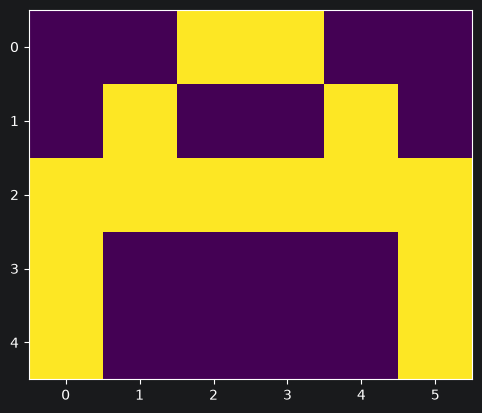

In [3]:
import numpy as np
import matplotlib.pyplot as plt
# Creating data set

# A
a =[0, 0, 1, 1, 0, 0,
   0, 1, 0, 0, 1, 0,
   1, 1, 1, 1, 1, 1,
   1, 0, 0, 0, 0, 1,
   1, 0, 0, 0, 0, 1]
# B
b =[0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 1, 0,
   0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 1, 0,
   0, 1, 1, 1, 1, 0]
# C
c =[0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 1, 1, 1, 0]

# Creating labels
y =[[1, 0, 0],
   [0, 1, 0],
   [0, 0, 1]]

# visualizing the data, plotting A.
plt.imshow(np.array(a).reshape(5, 6))
plt.show()

In [4]:
# converting data and labels into numpy array
x =[np.array(a).reshape(1, 30), np.array(b).reshape(1, 30),
                                np.array(c).reshape(1, 30)]
y = np.array(y)
# Printing data and labels
print(x, "\n\n", y)

[array([[0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
        0, 1, 1, 0, 0, 0, 0, 1]]), array([[0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
        1, 0, 0, 1, 1, 1, 1, 0]]), array([[0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 1, 1, 1, 1, 0]])] 

 [[1 0 0]
 [0 1 0]
 [0 0 1]]


In [9]:
# activation function
def sigmoid(x):
	return 1/(1 + np.exp(-x))

# Creating the Feed forward neural network
def f_forward(x, w1, w2):
	print(x.shape, w1.shape, w2.shape)
	z1 = x.dot(w1)    # input from layer 1
	a1 = sigmoid(z1)  # out put of layer 2
	z2 = a1.dot(w2)   # input of out layer
	a2 = sigmoid(z2)  # output of out layer
	print(a2.shape)
	return a2

# initializing the weights randomly
def generate_wt(x, y):
	li =[]
	for i in range(x * y):
		li.append(np.random.randn())
	return np.array(li).reshape(x, y)

# for loss we will be using mean square error(MSE)
def loss(out, Y):
	s =(np.square(out-Y))
	s = np.sum(s)/len(y)
	return s

# Back propagation of error
def back_prop(x, y, w1, w2, alpha):

	# hidden layer
	z1 = x.dot(w1)
	a1 = sigmoid(z1)
	z2 = a1.dot(w2)
	a2 = sigmoid(z2)

	# error in output layer
	d2 =(a2-y)
	d1 = np.multiply(w2.dot(d2.transpose()).transpose(),
								np.multiply(a1, 1-a1))
	# Gradient for w1 and w2
	w1_adj = x.transpose().dot(d1)
	w2_adj = a1.transpose().dot(d2)

	# Updating parameters
	w1 = w1-(alpha * w1_adj)
	w2 = w2-(alpha * w2_adj)

	return w1, w2

In [10]:
w1 = generate_wt(30, 5)
w2 = generate_wt(5, 3)

print(w1, "\n\n", w2)

[[ 0.80267733 -1.15392524  0.57403328  0.31542522  0.45478532]
 [-1.73694578 -0.23126998  1.87881576 -0.05715492 -0.96329529]
 [ 1.93415012  0.41387585 -1.1819591   0.24034783  0.36336529]
 [ 2.15218637 -0.85262404  1.36266792 -0.49671496  0.19345593]
 [ 1.98751659  0.96834003 -0.22820482 -0.64433281 -0.19507251]
 [ 1.21899591 -0.08547347 -0.76940777  1.05019893  0.05784318]
 [-0.28785779 -2.01954726 -0.49079306  0.42253488 -1.47381385]
 [ 0.61783211 -2.16770747  0.82954836  1.82042496  1.24043932]
 [-2.20533636  0.72720816 -0.20022423  0.92864313 -0.58204818]
 [-1.09308277  2.00772359 -0.37807012 -0.65728656 -1.55611059]
 [ 1.34945269 -0.00344528 -0.51379504 -0.27479811 -1.40071728]
 [-1.81767057 -1.88570836  1.86152215 -0.26026177  1.29058034]
 [ 0.15011251 -0.03598241  1.04669488 -0.2050487  -0.82916331]
 [-1.0160124   0.73843389 -0.25515677 -0.61672393 -0.08441836]
 [-0.64489247 -0.40490358  1.42415628  0.1851798  -0.14920009]
 [ 0.5034944   0.57302532 -0.49217299 -0.73475064 -0.09

(1, 30) (30, 5) (5, 3)
(1, 3)
epochs: 1 ======== acc: 85.75366196762558
(1, 30) (30, 5) (5, 3)
(1, 3)
epochs: 1 ======== acc: 78.26989980438377
(1, 30) (30, 5) (5, 3)
(1, 3)
epochs: 1 ======== acc: 63.283049223705405
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1,

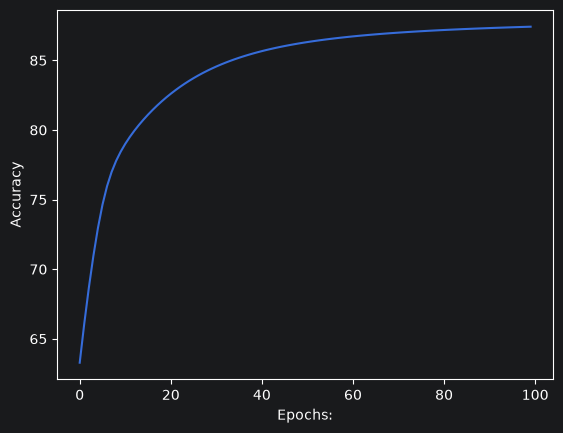

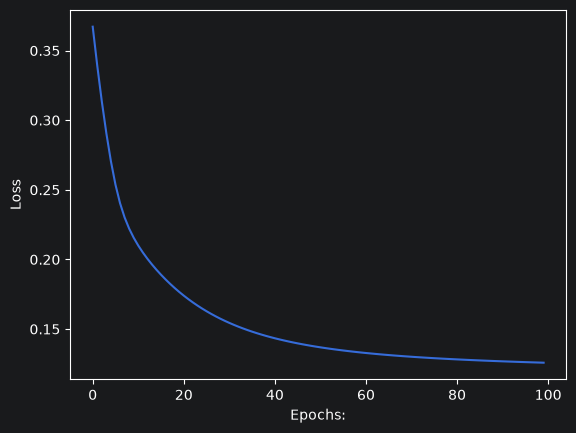

In [11]:
def train(x, Y, w1, w2, alpha = 0.01, epoch = 10):
	acc =[]
	losss =[]
	for j in range(epoch):
		l =[]
		for i in range(len(x)):
			out = f_forward(x[i], w1, w2)
			l.append(loss(out, Y[i]))
			w1, w2 = back_prop(x[i], y[i], w1, w2, alpha)
			if j % 10000 == 0:
				print("epochs:", j + 1, "======== acc:", (1-(sum(l)/len(x)))*100)
		acc.append((1-(sum(l)/len(x)))*100)
		losss.append(sum(l)/len(x))
	return acc, losss, w1, w2

acc, losss, w1, w2 = train(x, y, w1, w2, 0.1, 100)


# plotting accuracy
plt.plot(acc)
plt.ylabel('Accuracy')
plt.xlabel("Epochs:")
plt.show()

# plotting Loss
plt.plot(losss)
plt.ylabel('Loss')
plt.xlabel("Epochs:")
plt.show()

Image is of letter A.


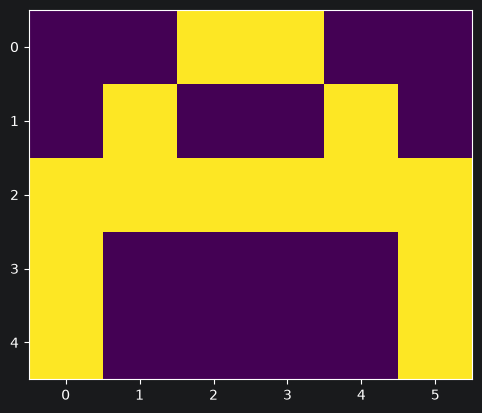

Image is of letter B.


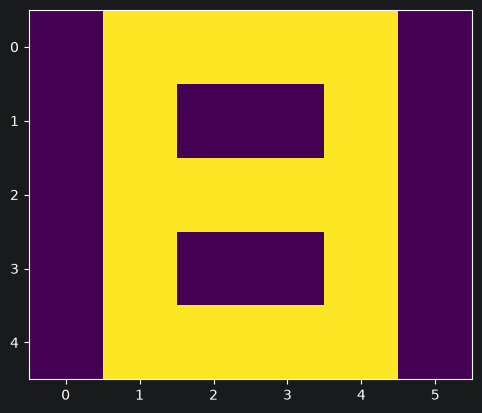

Image is of letter C.


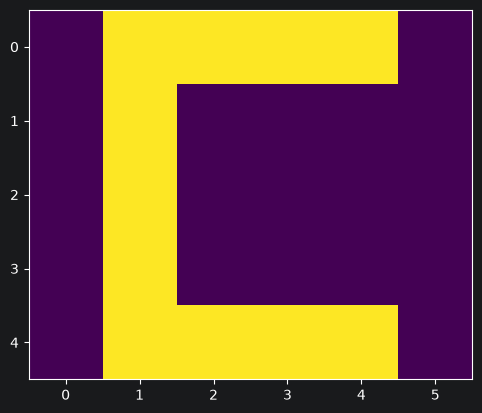

In [7]:
def predict(x, w1, w2):
	Out = f_forward(x, w1, w2)
	maxm = 0
	k = 0
	for i in range(len(Out[0])):
		if(maxm<Out[0][i]):
			maxm = Out[0][i]
			k = i
	if k == 0:
		print("Image is of letter A.")
	elif k == 1:
		print("Image is of letter B.")
	else:
		print("Image is of letter C.")
	plt.imshow(x.reshape(5, 6))
	plt.show()
# Example: Predicting for letter 'B'
for i in range(3):
	predict(x[i], w1, w2)